# 11 · Gradient Boosting in Practice — XGBoost, LightGBM & CatBoost

Notebook 05 built gradient boosting from first principles: fit small trees to the residuals, one after another. The libraries that dominate tabular ML — **XGBoost**, **LightGBM** and **CatBoost** — use the same core idea, plus a set of engineering and maths upgrades that make them faster, more accurate and easier to control.

**What you'll learn**
1. The **second-order** (Newton) maths behind XGBoost: gradients, Hessians, the optimal leaf value and the split-gain formula — 🐍 by hand on a toy example
2. **Histogram binning** — LightGBM's speed trick
3. A complete mini-XGBoost in 🔢 NumPy, checked against the real thing
4. 📦 The three libraries side by side: APIs, **early stopping**, missing values, **categorical features**
5. The hyperparameters that matter, with plots of what each one does
6. A tuning recipe with **Optuna**
7. Practical tools: class imbalance, **monotonic constraints**, feature importance types, saving models
8. When *not* to use gradient boosting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings, math
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=UserWarning)
# LightGBM ≥4.6 prefers fit(eval_X=..., eval_y=...) over eval_set=[...]; we keep eval_set so the
# notebook also runs on older versions, and silence the deprecation notice.
warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")

import xgboost as xgb, lightgbm as lgb, catboost as cb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from churn_utils import load_clean, CATEGORICAL
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| catboost", cb.__version__)

df, X, y = load_clean(with_features=False)
# three-way split: train (fit) / validation (early stopping, tuning) / test (final check)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=0, stratify=y_tmp)
print(f"train {len(y_train)} · validation {len(y_val)} · test {len(y_test)}")

xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10
train 3840 · validation 960 · test 1200


## 1. Recap, and what the libraries add

Gradient boosting builds the model as a sum of trees: $F(x) = f_0 + \eta\,h_1(x) + \eta\,h_2(x) + \dots$, where each new tree $h_m$ points in the direction that most reduces the loss — the **negative gradient** — and η is the learning rate (notebook 05).

| Upgrade | Who | Why it helps |
|---|---|---|
| **Second-order (Newton) steps** — use the curvature (Hessian) as well as the gradient | XGBoost (now all three) | better leaf values, a principled split score, any differentiable loss |
| **Regularisation in the objective** (λ on leaf values, γ per leaf) | XGBoost | less overfitting, built into split decisions |
| **Histogram binning** of features | LightGBM (now all three) | 10–100× faster split search, less memory |
| **Leaf-wise growth** (split the best leaf anywhere) | LightGBM | lower loss for the same number of leaves |
| **Native missing-value handling** — learn which way NaNs go | all three | no imputation needed |
| **Native categorical features** | LightGBM, CatBoost (best), XGBoost | no one-hot explosion; CatBoost avoids target leakage with *ordered* statistics |
| **Row & column subsampling** | all three | faster, and random-forest-like variance reduction |
| **Early stopping** on a validation set | all three | picks the number of trees automatically |

## 2. The second-order maths (XGBoost)

For each training example, we look at how the loss $\ell(y, F)$ changes if we nudge the current prediction $F$ (in log-odds). A second-order Taylor expansion around the current prediction:
$$ \ell(y, F + w) \approx \ell(y, F) + g\,w + \tfrac{1}{2}h\,w^2, \qquad g = \frac{\partial \ell}{\partial F},\; h = \frac{\partial^2 \ell}{\partial F^2} $$

For **log-loss** with $p = \sigma(F)$: $\;g = p - y\;$ and $\;h = p(1-p)$.

A leaf adds the same value $w$ to every example in it. Summing over the leaf's examples ($G = \sum g$, $H = \sum h$) and adding an L2 penalty $\frac{\lambda}{2}w^2$, the loss change is $Gw + \frac12(H+\lambda)w^2$. It's a parabola, so set the derivative to zero:
$$ \boxed{\,w^* = -\frac{G}{H + \lambda}\,} \qquad\text{reducing the loss by}\qquad \frac{1}{2}\frac{G^2}{H+\lambda} $$

So a split is worth the improvement of the children over the parent, minus a cost γ for the extra leaf:
$$ \boxed{\,\text{Gain} = \frac12\left[\frac{G_L^2}{H_L+\lambda} + \frac{G_R^2}{H_R+\lambda} - \frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right] - \gamma\,} $$

If the best gain is ≤ 0, don't split. **λ** shrinks leaf values; **γ** prunes weak splits. That's the whole XGBoost tree-building rule.

In [2]:
# 🐍 Pure Python: one boosting step on 6 customers, by hand
import math
ys = [1, 1, 0, 0, 1, 0]
xs = [2, 3, 10, 14, 4, 20]          # e.g. tenure in months
F = [0.0] * 6                        # start: log-odds 0 → p = 0.5 for everyone
lam, gamma = 1.0, 0.0

p = [1 / (1 + math.exp(-f)) for f in F]
g = [pi - yi for pi, yi in zip(p, ys)]                 # gradients
h = [pi * (1 - pi) for pi in p]                        # Hessians
print("g =", g, "\nh =", h)

def score(G, H): return G * G / (H + lam)

best = None
for t in sorted(set(xs))[1:]:                          # try every threshold "x < t"
    L = [i for i in range(6) if xs[i] < t]; R = [i for i in range(6) if xs[i] >= t]
    GL, HL = sum(g[i] for i in L), sum(h[i] for i in L); GR, HR = sum(g[i] for i in R), sum(h[i] for i in R)
    gain = 0.5 * (score(GL, HL) + score(GR, HR) - score(GL + GR, HL + HR)) - gamma
    print(f"split x < {t:2d}: gain = {gain:.3f}")
    if best is None or gain > best[0]:
        best = (gain, t, -GL / (HL + lam), -GR / (HR + lam))
print(f"\nbest split x < {best[1]}; leaf values: left {best[2]:+.3f}, right {best[3]:+.3f}  (in log-odds)")

g = [-0.5, -0.5, 0.5, 0.5, -0.5, 0.5] 
h = [0.25, 0.25, 0.25, 0.25, 0.25, 0.25]
split x <  3: gain = 0.156
split x <  4: gain = 0.583
split x < 10: gain = 1.286
split x < 14: gain = 0.583
split x < 20: gain = 0.156

best split x < 10; leaf values: left +0.857, right -0.857  (in log-odds)


The left leaf (short tenure, all churners) gets a **positive** value (pushes toward churn), the right leaf a negative one. Notice λ = 1 keeps the values modest even though both leaves are pure — that's the regularisation at work.

## 3. Histogram binning — the speed trick

Exact split search sorts every feature at every node: $O(n \log n)$ per feature per node. Instead, **bin each feature once** into ≤ 256 buckets (by quantiles). At each node, sum $g$ and $h$ per bucket with a single pass — a **histogram** — and try only bucket boundaries. Cost per node: $O(n)$ to build the histogram + $O(\text{bins})$ to scan it.

Bonus tricks: a child's histogram = parent's − sibling's (build only the smaller child), and bins need only 1 byte per value.

In [3]:
# 🔢 Binning by quantiles, and the cost difference in practice
def make_bins(X_arr, max_bins=64):
    """Return integer bin codes (n, d) and the bin edges per feature. NaN → its own bin 0."""
    codes = np.zeros(X_arr.shape, dtype=np.int32); edges = []
    for j in range(X_arr.shape[1]):
        col = X_arr[:, j]; ok = ~np.isnan(col)
        e = np.unique(np.quantile(col[ok], np.linspace(0, 1, max_bins + 1)[1:-1]))
        codes[ok, j] = np.searchsorted(e, col[ok], side="right") + 1      # bins 1..len(e)+1
        edges.append(e)
    return codes, edges

rng = np.random.default_rng(0)
big = rng.normal(size=(200_000, 1)); gb_ = rng.normal(size=200_000); hb = np.ones(200_000)

t0 = time.perf_counter()                                 # exact: sort, cumulative sums, every threshold
o = np.argsort(big[:, 0]); GL = np.cumsum(gb_[o]); HL = np.cumsum(hb[o])
t_exact = time.perf_counter() - t0
codes, _ = make_bins(big, 255)
t0 = time.perf_counter()                                 # histogram: one bincount, then 255 thresholds
Gh = np.bincount(codes[:, 0], weights=gb_); Hh = np.bincount(codes[:, 0], weights=hb)
GLh, HLh = np.cumsum(Gh), np.cumsum(Hh)
t_hist = time.perf_counter() - t0
print(f"exact split search: {t_exact * 1000:.1f} ms · histogram: {t_hist * 1000:.2f} ms  → {t_exact / t_hist:.0f}x faster, for ONE feature at ONE node")

exact split search: 9.4 ms · histogram: 1.25 ms  → 7x faster, for ONE feature at ONE node


## 4. 🔢 A mini-XGBoost in NumPy

Everything from Sections 2–3 in one class: Newton leaf values, the gain formula with λ and γ, histogram split search, a learning rate, depth limit and minimum Hessian per leaf (`min_child_weight`).

In [4]:
class MiniXGBClassifier:
    def __init__(self, n_estimators=200, learning_rate=0.1, max_depth=3, reg_lambda=1.0, gamma=0.0,
                 min_child_weight=1.0, max_bins=64):
        self.n_estimators, self.lr, self.max_depth = n_estimators, learning_rate, max_depth
        self.lam, self.gamma, self.mcw, self.max_bins = reg_lambda, gamma, min_child_weight, max_bins

    def _build(self, idx, g, h, depth):
        G, H = g[idx].sum(), h[idx].sum()
        leaf = -G / (H + self.lam)
        if depth == self.max_depth or len(idx) < 2:
            return leaf
        best_gain, best = 0.0, None
        parent = G * G / (H + self.lam)
        for j in range(self.codes.shape[1]):
            b = self.codes[idx, j]
            Gb = np.bincount(b, weights=g[idx], minlength=self.n_bins[j])     # gradient histogram
            Hb = np.bincount(b, weights=h[idx], minlength=self.n_bins[j])     # Hessian histogram
            GL, HL = np.cumsum(Gb)[:-1], np.cumsum(Hb)[:-1]                   # left = bins ≤ k
            GR, HR = G - GL, H - HL
            gain = 0.5 * (GL**2 / (HL + self.lam) + GR**2 / (HR + self.lam) - parent) - self.gamma
            gain[(HL < self.mcw) | (HR < self.mcw)] = -np.inf               # each child needs enough "weight"
            k = int(np.argmax(gain))
            if gain[k] > best_gain:
                best_gain, best = gain[k], (j, k)
        if best is None:
            return leaf
        j, k = best; go_left = self.codes[idx, j] <= k
        return (j, k, self._build(idx[go_left], g, h, depth + 1), self._build(idx[~go_left], g, h, depth + 1))

    def _predict_tree(self, node, codes):
        out = np.empty(len(codes)); stack = [(node, np.arange(len(codes)))]
        while stack:
            nd, rows = stack.pop()
            if not isinstance(nd, tuple):
                out[rows] = nd; continue
            j, k, l, r = nd; m = codes[rows, j] <= k
            stack += [(l, rows[m]), (r, rows[~m])]
        return out

    def _encode(self, X_arr):                   # apply TRAINING bin edges to any data
        codes = np.zeros(X_arr.shape, dtype=np.int32)
        for j, e in enumerate(self.edges):
            ok = ~np.isnan(X_arr[:, j]); codes[ok, j] = np.searchsorted(e, X_arr[ok, j], side="right") + 1
        return codes

    def fit(self, X_arr, y, X_val=None, y_val=None):
        self.codes, self.edges = make_bins(X_arr, self.max_bins)
        self.n_bins = [len(e) + 2 for e in self.edges]
        self.base = math.log(y.mean() / (1 - y.mean()))          # start from the overall log-odds
        F = np.full(len(y), self.base); self.trees, self.val_auc = [], []
        Fv = np.full(len(y_val), self.base) if X_val is not None else None
        cv_ = self._encode(X_val) if X_val is not None else None
        for _ in range(self.n_estimators):
            p = 1 / (1 + np.exp(-F)); g, h = p - y, p * (1 - p)
            tree = self._build(np.arange(len(y)), g, h, 0)
            F += self.lr * self._predict_tree(tree, self.codes); self.trees.append(tree)
            if Fv is not None:
                Fv += self.lr * self._predict_tree(tree, cv_); self.val_auc.append(roc_auc_score(y_val, Fv))
        return self

    def decision_function(self, X_arr):
        codes = self._encode(X_arr)
        return self.base + self.lr * sum(self._predict_tree(t, codes) for t in self.trees)

    def predict_proba(self, X_arr):
        p = 1 / (1 + np.exp(-self.decision_function(X_arr))); return np.column_stack([1 - p, p])

# Integer-code categories so everything is numeric (NaNs are left as NaN — they get their own bin)
cats_fixed = {c: sorted(X[c].unique()) for c in CATEGORICAL}
def to_numeric_fixed(D):
    D = D.copy()
    for c in CATEGORICAL: D[c] = D[c].map({v: i for i, v in enumerate(cats_fixed[c])}).astype(float)
    return D.to_numpy(float)
Xtr_n, Xva_n, Xte_n = to_numeric_fixed(X_train), to_numeric_fixed(X_val), to_numeric_fixed(X_test)

t0 = time.perf_counter()
mini = MiniXGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, reg_lambda=1.0, min_child_weight=5).fit(Xtr_n, y_train, Xva_n, y_val)
t_mini = time.perf_counter() - t0
real = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, reg_lambda=1.0, min_child_weight=5,
                         tree_method="hist", max_bin=64).fit(Xtr_n, y_train)
print(f"our mini-XGBoost: test AUC {roc_auc_score(y_test, mini.predict_proba(Xte_n)[:, 1]):.4f}  ({t_mini:.1f}s)")
print(f"real XGBoost:     test AUC {roc_auc_score(y_test, real.predict_proba(Xte_n)[:, 1]):.4f}")
print(f"correlation of their predicted log-odds: {np.corrcoef(mini.decision_function(Xte_n), real.predict(Xte_n, output_margin=True))[0, 1]:.3f}")

our mini-XGBoost: test AUC 0.8196  (1.0s)
real XGBoost:     test AUC 0.8204
correlation of their predicted log-odds: 0.992


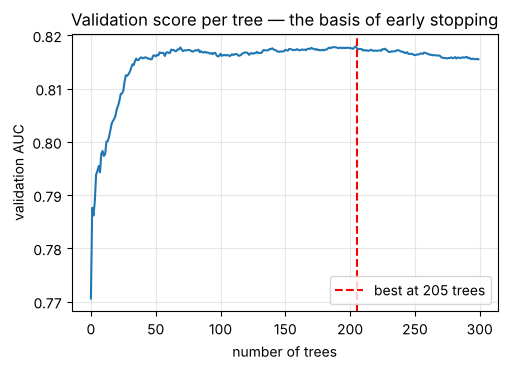

In [5]:
plt.plot(mini.val_auc); plt.xlabel("number of trees"); plt.ylabel("validation AUC")
best_n = int(np.argmax(mini.val_auc)) + 1
plt.axvline(best_n, ls="--", c="r", label=f"best at {best_n} trees"); plt.legend()
plt.title("Validation score per tree — the basis of early stopping"); plt.show()

## 5. 📦 The three libraries

All three offer a scikit-learn-style API (`fit` / `predict_proba`). The standard workflow:
1. Set a **large** `n_estimators` and a moderate learning rate.
2. Pass a **validation set** and `early_stopping_rounds`: training stops when the validation score hasn't improved for that many rounds, and the best iteration is used for prediction.
3. Tune the tree-shape and regularisation parameters (Section 6).

⚠️ Early stopping *uses* the validation set to choose the number of trees, so report final performance on a separate **test** set.

**Categorical features:**
- **XGBoost:** pandas `category` dtype + `enable_categorical=True`.
- **LightGBM:** pandas `category` dtype is detected automatically.
- **CatBoost:** pass raw strings and list them in `cat_features`. CatBoost encodes them with *ordered target statistics* (an out-of-fold-like target encoding — notebook 08) — usually the strongest option when there are many categorical columns.

**Missing values:** all three learn, at each split, which side NaNs should go to. No imputation needed.

In [6]:
def as_category(D):
    D = D.copy()
    for c in CATEGORICAL: D[c] = pd.Categorical(D[c], categories=cats_fixed[c])
    return D
Xtr_c, Xva_c, Xte_c = as_category(X_train), as_category(X_val), as_category(X_test)
results = {}

# XGBoost
t0 = time.perf_counter()
xgb_model = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                              tree_method="hist", enable_categorical=True, eval_metric="auc", early_stopping_rounds=100)
xgb_model.fit(Xtr_c, y_train, eval_set=[(Xva_c, y_val)], verbose=False)
results["XGBoost"] = (roc_auc_score(y_test, xgb_model.predict_proba(Xte_c)[:, 1]), xgb_model.best_iteration + 1, time.perf_counter() - t0)

# LightGBM
t0 = time.perf_counter()
lgb_model = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, verbose=-1)
lgb_model.fit(Xtr_c, y_train, eval_set=[(Xva_c, y_val)], eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
results["LightGBM"] = (roc_auc_score(y_test, lgb_model.predict_proba(Xte_c)[:, 1]), lgb_model.best_iteration_, time.perf_counter() - t0)

# CatBoost — raw string categories
t0 = time.perf_counter()
cb_model = cb.CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=4, eval_metric="AUC", cat_features=CATEGORICAL,
                                 verbose=0, allow_writing_files=False, random_seed=0)
cb_model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=100)
results["CatBoost"] = (roc_auc_score(y_test, cb_model.predict_proba(X_test)[:, 1]), cb_model.get_best_iteration() + 1, time.perf_counter() - t0)

# Our mini version, with the number of trees chosen on validation, and sklearn's built-in
from sklearn.ensemble import HistGradientBoostingClassifier
results["mini-XGBoost (ours)"] = (roc_auc_score(y_test, MiniXGBClassifier(n_estimators=best_n, learning_rate=0.05, max_depth=3,
                                  min_child_weight=5).fit(Xtr_n, y_train).predict_proba(Xte_n)[:, 1]), best_n, t_mini)
t0 = time.perf_counter()
hgb = HistGradientBoostingClassifier(max_iter=3000, learning_rate=0.03, max_leaf_nodes=15, early_stopping=True,
                                     validation_fraction=0.2, n_iter_no_change=100, scoring="roc_auc",
                                     categorical_features="from_dtype", random_state=0).fit(as_category(X_tmp), y_tmp)
results["sklearn HistGB"] = (roc_auc_score(y_test, hgb.predict_proba(Xte_c)[:, 1]), hgb.n_iter_, time.perf_counter() - t0)

pd.DataFrame(results, index=["test AUC", "trees used", "fit seconds"]).T.round(4)

,test AUC,trees used,fit seconds
XGBoost,0.8200,172.0,0.2057
LightGBM,0.8209,107.0,0.4086
CatBoost,0.8169,209.0,0.8569
mini-XGBoost (ours),0.8198,205.0,1.0239
sklearn HistGB,0.8167,198.0,0.8892


On a dataset this size, all of them land within noise of each other — the choice of library rarely matters as much as features, validation and tuning. Rough guidance:
- **LightGBM:** fastest on large data; leaf-wise trees (watch `num_leaves` / `min_child_samples` on small data).
- **XGBoost:** the most widely deployed; excellent docs; strong GPU support.
- **CatBoost:** best out-of-the-box with many categorical columns; symmetric ("oblivious") trees make prediction very fast and resist overfitting; good defaults.

## 6. The hyperparameters that matter

| Group | XGBoost | LightGBM | CatBoost | Effect |
|---|---|---|---|---|
| Step size | `learning_rate` | `learning_rate` | `learning_rate` | smaller = needs more trees, usually generalises better |
| Number of trees | `n_estimators` + early stopping | same | `iterations` + early stopping | let early stopping pick it |
| Tree size | `max_depth` | `num_leaves` (+`max_depth`) | `depth` | complexity / interactions captured |
| Leaf size | `min_child_weight` (Hessian sum) | `min_child_samples` | `min_data_in_leaf` | bigger = smoother, less overfitting |
| Row sampling | `subsample` | `subsample` + `subsample_freq` | `subsample` / `bootstrap_type` | randomness → less variance, faster |
| Column sampling | `colsample_bytree` | `colsample_bytree` | `rsm` | decorrelates trees |
| Regularisation | `reg_lambda`, `reg_alpha`, `gamma` | `reg_lambda`, `reg_alpha`, `min_split_gain` | `l2_leaf_reg` | shrinks leaves / prunes splits |

### 6.1 Learning rate vs number of trees

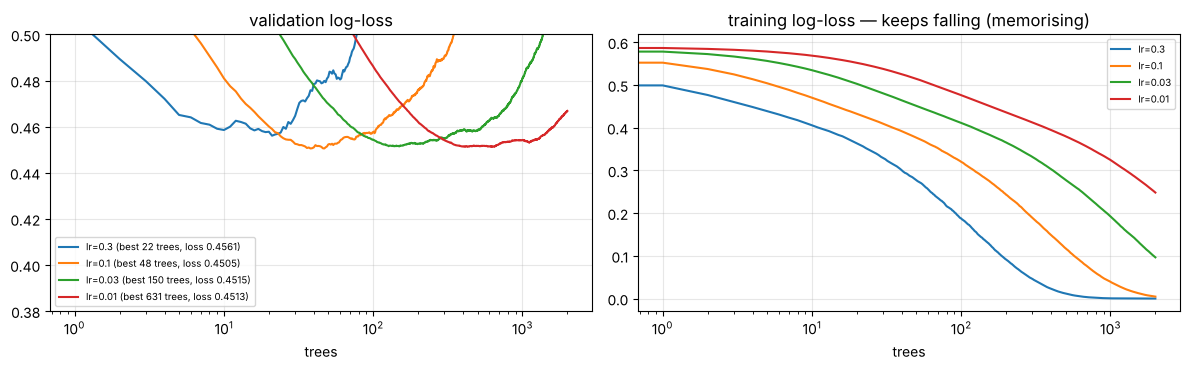

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lr_ in [0.3, 0.1, 0.03, 0.01]:
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=lr_, num_leaves=15, verbose=-1)
    m.fit(Xtr_c, y_train, eval_set=[(Xtr_c, y_train), (Xva_c, y_val)], eval_metric="binary_logloss")
    tr, va = m.evals_result_["training"]["binary_logloss"], m.evals_result_["valid_1"]["binary_logloss"]
    ax[0].plot(va, label=f"lr={lr_} (best {np.argmin(va) + 1} trees, loss {min(va):.4f})")
    ax[1].plot(tr, label=f"lr={lr_}")
ax[0].set_title("validation log-loss"); ax[1].set_title("training log-loss — keeps falling (memorising)")
for a in ax: a.set_xlabel("trees"); a.set_xscale("log"); a.legend(fontsize=7)
ax[0].set_ylim(0.38, 0.5); plt.tight_layout(); plt.show()

Big learning rates reach their best fast and then **overfit** (validation loss climbs back up). Small learning rates need many more trees but usually reach an equal or slightly lower minimum. Practical rule: tune other parameters at lr ≈ 0.05–0.1 (fast), then lower it to 0.01–0.03 with early stopping for the final model.

### 6.2 Tree complexity and leaf size

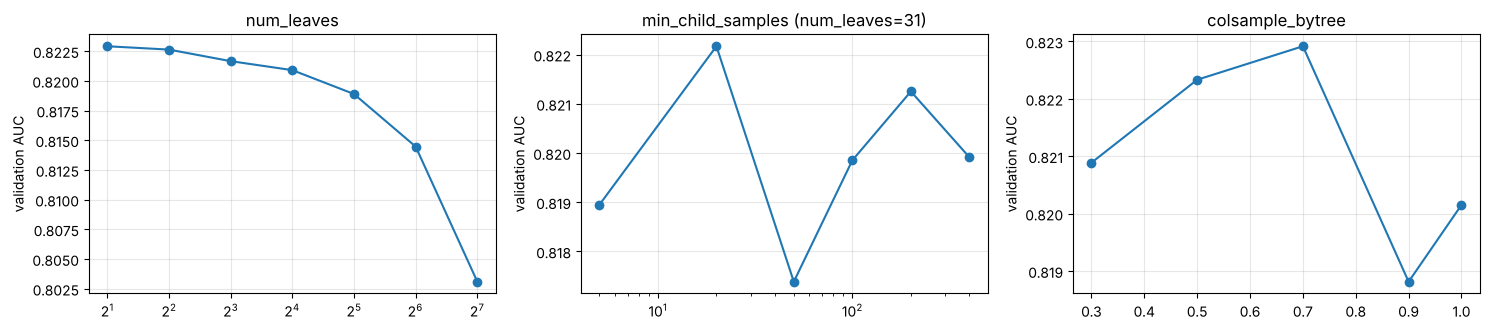

In [8]:
def val_auc(**params):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, verbose=-1, **params)
    m.fit(Xtr_c, y_train, eval_set=[(Xva_c, y_val)], eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.best_score_["valid_0"]["auc"]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
leaves = [2, 4, 8, 16, 32, 64, 128]
ax[0].plot(leaves, [val_auc(num_leaves=n) for n in leaves], "o-"); ax[0].set_xscale("log", base=2); ax[0].set_title("num_leaves")
mcs = [5, 20, 50, 100, 200, 400]
ax[1].plot(mcs, [val_auc(num_leaves=31, min_child_samples=m) for m in mcs], "o-"); ax[1].set_xscale("log"); ax[1].set_title("min_child_samples (num_leaves=31)")
subs = [0.3, 0.5, 0.7, 0.9, 1.0]
ax[2].plot(subs, [val_auc(num_leaves=15, colsample_bytree=s) for s in subs], "o-"); ax[2].set_title("colsample_bytree")
for a in ax: a.set_ylabel("validation AUC")
plt.tight_layout(); plt.show()

Our churn mechanism is fairly simple (mostly additive effects plus one interaction), so **small trees** (2–8 leaves) do best and big trees overfit unless leaves are forced to be large. On data with many interacting features, the optimum shifts toward bigger trees. That's why you tune instead of copying settings.

Also notice the y-axis scales: the middle and right panels move by only ~0.003 AUC, which is **within noise** for a 960-row validation set — those zig-zags aren't real effects. Only `num_leaves` shows a clear trend. Single validation scores are noisy, so look for consistent trends (or use cross-validation) rather than chasing the highest dot.

## 7. Tuning recipe with Optuna

1. Fix a moderate learning rate (0.05); use early stopping for the number of trees.
2. Tune tree shape + leaf size + sampling + regularisation (log scales for λ and sizes).
3. Lower the learning rate for the final fit; refit with early stopping.
4. Check on the test set **once**.

In [9]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        num_leaves=trial.suggest_int("num_leaves", 2, 64, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
    )
    return val_auc(**params)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=30)
print(f"best validation AUC {study.best_value:.4f} with {study.best_params}")

final = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.01, subsample_freq=1, verbose=-1, **study.best_params)
final.fit(Xtr_c, y_train, eval_set=[(Xva_c, y_val)], eval_metric="auc", callbacks=[lgb.early_stopping(200, verbose=False)])
print(f"final model: {final.best_iteration_} trees at lr=0.01 → TEST AUC {roc_auc_score(y_test, final.predict_proba(Xte_c)[:, 1]):.4f}")

best validation AUC 0.8266 with {'num_leaves': 5, 'min_child_samples': 137, 'subsample': 0.6804402077356196, 'colsample_bytree': 0.568098117766814, 'reg_lambda': 0.010211625734061995}


final model: 1008 trees at lr=0.01 → TEST AUC 0.8272


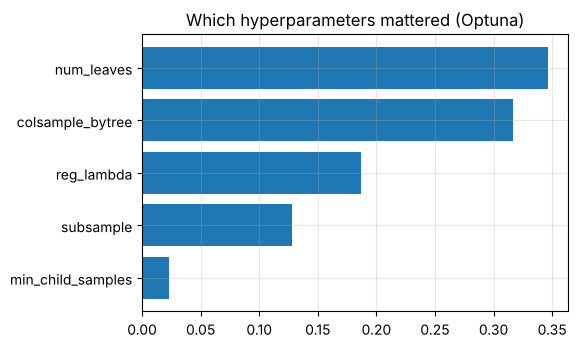

In [10]:
imp = optuna.importance.get_param_importances(study)
plt.barh(list(imp)[::-1], list(imp.values())[::-1]); plt.title("Which hyperparameters mattered (Optuna)"); plt.show()

## 8. Practical tools

### 8.1 Class imbalance
Options: leave it (boosting with log-loss gives good *probabilities*; then move the threshold — notebook 09), or re-weight positives with `scale_pos_weight` (XGBoost/LightGBM) ≈ negatives / positives, or `auto_class_weights="Balanced"` (CatBoost). Re-weighting raises recall at a given threshold but **distorts probabilities** — recalibrate if you need them.

In [11]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
for w in [1.0, spw]:
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, scale_pos_weight=w, enable_categorical=True,
                          tree_method="hist").fit(Xtr_c, y_train)
    p = m.predict_proba(Xte_c)[:, 1]
    print(f"scale_pos_weight={w:.2f}: AUC {roc_auc_score(y_test, p):.4f} | mean predicted p {p.mean():.3f} (true rate {y_test.mean():.3f}) | recall@0.5 {np.mean(p[y_test == 1] >= 0.5):.3f}")

scale_pos_weight=1.00: AUC 0.8184 | mean predicted p 0.280 (true rate 0.278) | recall@0.5 0.482


scale_pos_weight=2.60: AUC 0.8185 | mean predicted p 0.418 (true rate 0.278) | recall@0.5 0.731


AUC (ranking) is unchanged, but the re-weighted model's probabilities are inflated — fine for ranking, wrong for "expected profit" maths.

### 8.2 Monotonic constraints — encode domain knowledge
We *believe* churn risk should never go **up** with longer tenure or higher satisfaction, and never go **down** with more support calls. Tell the model, and it can't learn noisy wiggles that contradict that: more trustworthy, easier to explain, often better on new data.

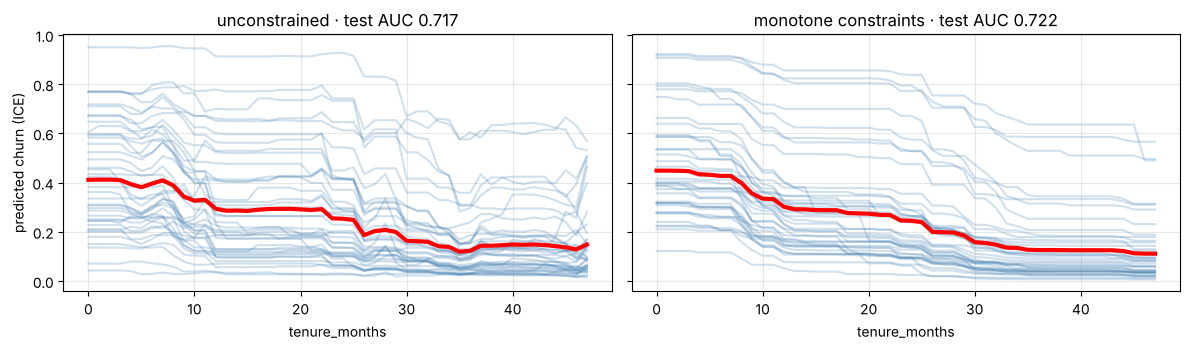

In [12]:
mono = {c: 0 for c in X.columns}
mono.update({"tenure_months": -1, "satisfaction_score": -1, "support_calls": +1, "last_login_days_ago": +1})
Xtr_m, Xte_m = Xtr_c.drop(columns=CATEGORICAL), Xte_c.drop(columns=CATEGORICAL)    # numeric features only, for a clean demo
cons = tuple(mono[c] for c in Xtr_m.columns)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for a, (name, c) in zip(ax, [("unconstrained", None), ("monotone constraints", cons)]):
    m = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, monotone_constraints=c, tree_method="hist").fit(Xtr_m, y_train)
    grid = np.arange(0, 48); rows = Xte_m.sample(200, random_state=0)
    curves = np.array([m.predict_proba(rows.assign(tenure_months=v))[:, 1] for v in grid]).T
    a.plot(grid, curves[:40].T, c="steelblue", alpha=0.25); a.plot(grid, curves.mean(0), c="r", lw=3)
    a.set_title(f"{name} · test AUC {roc_auc_score(y_test, m.predict_proba(Xte_m)[:, 1]):.3f}"); a.set_xlabel("tenure_months")
ax[0].set_ylabel("predicted churn (ICE)"); plt.tight_layout(); plt.show()

### 8.3 Built-in feature importance — know which kind you're reading
- **split / weight:** how many times a feature is used. Biased toward high-cardinality numeric features.
- **gain:** total loss reduction from splits on the feature. Better, still training-set based.
- **cover:** how many samples pass through those splits.

They often disagree. For decisions, prefer **permutation importance** or **SHAP** on held-out data (notebook 10).

In [13]:
booster = xgb_model.get_booster()
imp_df = pd.DataFrame({k: pd.Series(booster.get_score(importance_type=k)) for k in ["weight", "gain", "cover"]}).fillna(0)
(imp_df / imp_df.sum()).sort_values("gain", ascending=False).round(3)

,weight,gain,cover
contract,0.054,0.295,0.180
satisfaction_score,0.065,0.104,0.091
tenure_months,0.095,0.087,0.080
support_calls,0.061,0.074,0.102
plan,0.020,0.071,0.064
last_login_days_ago,0.105,0.065,0.074
monthly_charges,0.144,0.062,0.067
total_charges,0.106,0.051,0.055
payment_method,0.049,0.044,0.063
has_partner,0.014,0.040,0.087


### 8.4 Saving and loading
Use each library's native format — it's stable across versions and can be loaded from other languages (C++, Java…), unlike pickle/joblib.

In [14]:
from pathlib import Path
Path("models").mkdir(exist_ok=True)
xgb_model.save_model("models/churn_xgb.json")
final.booster_.save_model("models/churn_lgb.txt")
cb_model.save_model("models/churn_catboost.cbm")

re_xgb = xgb.XGBClassifier(); re_xgb.load_model("models/churn_xgb.json")
print("reloaded XGBoost gives identical predictions:", np.allclose(re_xgb.predict_proba(Xte_c), xgb_model.predict_proba(Xte_c)))

reloaded XGBoost gives identical predictions: True


## 9. When *not* to use gradient boosting
- **Images, audio, text, video:** raw pixels/tokens → deep learning (CNNs, transformers). Boosting shines on *tabular* features.
- **Extrapolation:** trees predict a constant beyond the training range; a price-trend forecast that must go above anything seen needs a model that can extrapolate (linear terms, or model the trend separately).
- **Tiny datasets** (hundreds of rows): regularised linear models or small random forests are often as good and more stable.
- **Strict interpretability requirements:** a linear model / scorecard / small tree may be required — or boosting with monotonic constraints + SHAP.
- **When a linear model is just as good** (as in notebook 09!): prefer the simpler model.

## Key takeaways
- XGBoost-style boosting uses gradients **and** Hessians: leaf value $-G/(H+\lambda)$; split gain from $G^2/(H+\lambda)$ terms, minus γ.
- **Histogram binning** makes split search fast; all major libraries use it.
- Always use **early stopping** on a validation set; report on a separate test set.
- The knobs that matter: learning rate (+ trees), tree size, leaf size, row/column sampling, L2.
- Use native categorical and missing-value handling; add **monotonic constraints** where domain knowledge is solid.
- Library choice matters less than features, validation and tuning.

## Exercises
1. Add `reg_alpha` (L1 on leaf values) to `MiniXGBClassifier`. Hint: the optimal leaf becomes $-\text{soft-threshold}(G, \alpha)/(H+\lambda)$.
2. Change `MiniXGBClassifier` to **regression** with squared loss. What are $g$ and $h$? (Answer: $g = F - y$, $h = 1$ — and the algorithm becomes notebook 05's residual fitting.)
3. Generate a 500,000-row dataset with `sklearn.datasets.make_classification` and time XGBoost, LightGBM and CatBoost with 200 trees each.
4. Train CatBoost with `cat_features` vs with integer-coded categories (no `cat_features`). Compare test AUC.

In [15]:
# Exercise 2 — solution: with squared loss, g = F − y (minus the residual) and h = 1,
# so the leaf value −G/(H+λ) is just the (shrunk) mean residual — notebook 05's algorithm.
F_demo, y_demo = np.zeros(5), np.array([3.0, 1.0, 4.0, 1.0, 5.0])
g_demo, h_demo = F_demo - y_demo, np.ones(5)
print("leaf value with λ=0:", -g_demo.sum() / h_demo.sum(), "= mean residual", (y_demo - F_demo).mean())

leaf value with λ=0: 2.8 = mean residual 2.8


**🎉 That completes notebooks 00–11.** You can now take a messy table, clean it, model it, tune it, explain it, and ship it.

**Next:** [12 · Time Series Forecasting](12_time_series.ipynb) — Part 3 starts with data that arrives in order over time.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §3.8 (boosting) · `Calculus_Notes.md` Part 6 (Taylor expansion) and §8.4 (Newton's method — the maths behind second-order boosting) · code: `ml_from_scratch_part2.py` → `XGBoostStyleBooster`, `ml_from_scratch.py` → `GradientBoostingRegressor`.